In [14]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, r2_score

In [15]:
da=pd.read_csv("insurance.csv")
da

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [16]:
da.head

<bound method NDFrame.head of       age     sex     bmi  children smoker     region      charges
0      19  female  27.900         0    yes  southwest  16884.92400
1      18    male  33.770         1     no  southeast   1725.55230
2      28    male  33.000         3     no  southeast   4449.46200
3      33    male  22.705         0     no  northwest  21984.47061
4      32    male  28.880         0     no  northwest   3866.85520
...   ...     ...     ...       ...    ...        ...          ...
1333   50    male  30.970         3     no  northwest  10600.54830
1334   18  female  31.920         0     no  northeast   2205.98080
1335   18  female  36.850         0     no  southeast   1629.83350
1336   21  female  25.800         0     no  southwest   2007.94500
1337   61  female  29.070         0    yes  northwest  29141.36030

[1338 rows x 7 columns]>

In [17]:
da_encoded = pd.get_dummies(da, drop_first=True)

In [18]:
da.shape

(1338, 7)

In [19]:
da['charges']

0       16884.92400
1        1725.55230
2        4449.46200
3       21984.47061
4        3866.85520
           ...     
1333    10600.54830
1334     2205.98080
1335     1629.83350
1336     2007.94500
1337    29141.36030
Name: charges, Length: 1338, dtype: float64

In [20]:
x=da.drop('charges',axis=1)
y = da['charges']

# 3. تقسيم البيانات إلى تدريب (80%) واختبار (20%)

In [26]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)


In [27]:
# تحويل النصوص إلى أرقام بعد التقسيم (لتجنب أي تسرب للبيانات)
X_train_enc = pd.get_dummies(X_train, drop_first=True)
X_test_enc = pd.get_dummies(X_test, drop_first=True)

In [28]:
# ضمان تطابق الأعمدة بين التدريب والاختبار
X_test_enc = X_test_enc.reindex(columns=X_train_enc.columns, fill_value=0)

# توحيد المقاييس
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train_enc)
X_test_scaled = scaler_X.transform(X_test_enc)
y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1)).ravel()

# بناء وتدريب نموذج SVR
model = SVR(kernel='rbf', C=100, gamma=0.1, epsilon=0.1)
model.fit(X_train_scaled, y_train_scaled)

# التنبؤ وإرجاع القيم إلى مقياسها الأصلي
predictions_scaled = model.predict(X_test_scaled)
predictions = scaler_y.inverse_transform(predictions_scaled.reshape(-1, 1)).ravel()

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# ضبط النمط العام للرسوم
sns.set_theme(style="whitegrid")

# تقييم النموذج
print("MAE (متوسط الخطأ):", round(mean_absolute_error(y_test, predictions), 2))
print("R2 Score (دقة النموذج):", round(r2_score(y_test, predictions), 2))

MAE (متوسط الخطأ): 2617.75
R2 Score (دقة النموذج): 0.85


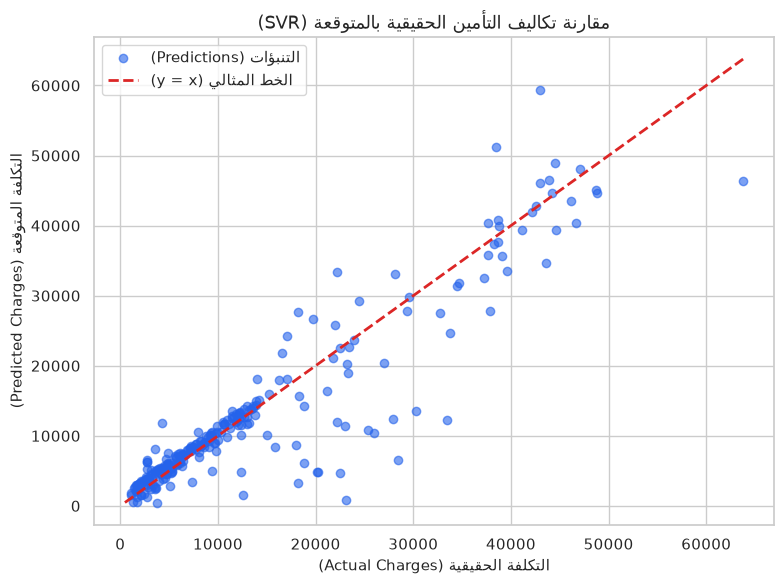

In [31]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, predictions, alpha=0.6, color="#2563eb", label="التنبؤات (Predictions)")

# خط المثالية (حيث تساوي القيمة المتوقعة القيمة الحقيقية)
min_val = min(y_test.min(), predictions.min())
max_val = max(y_test.max(), predictions.max())
plt.plot([min_val, max_val], [min_val, max_val], color="#dc2626", linestyle="--", linewidth=2, label="الخط المثالي (y = x)")

plt.title("مقارنة تكاليف التأمين الحقيقية بالمتوقعة (SVR)", fontsize=13)
plt.xlabel("التكلفة الحقيقية (Actual Charges)", fontsize=11)
plt.ylabel("التكلفة المتوقعة (Predicted Charges)", fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()

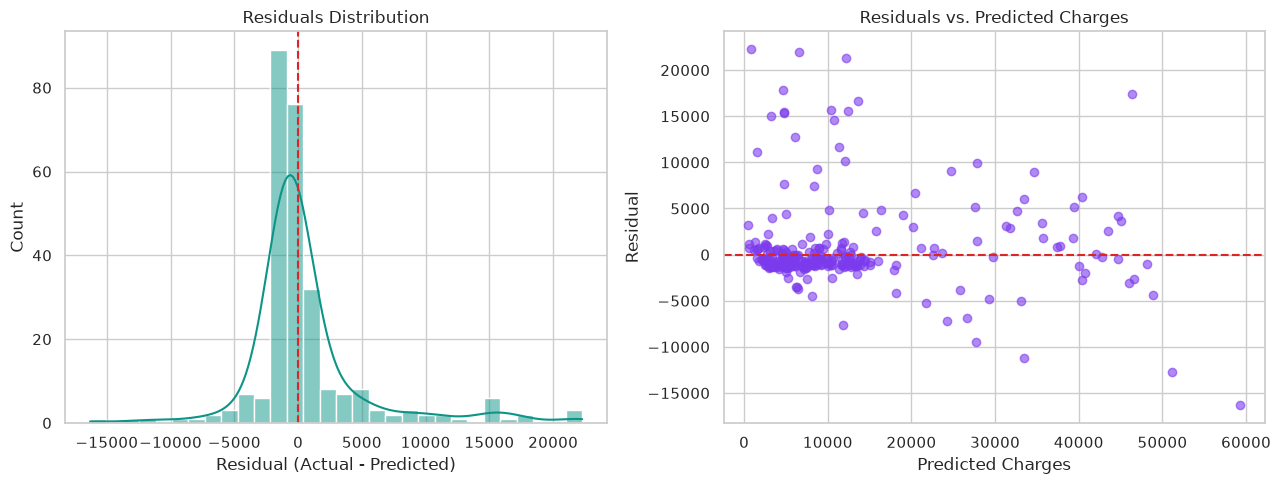

In [35]:
residuals = y_test - predictions

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# توزيع الأخطاء
sns.histplot(residuals, kde=True, bins=30, color="#0d9488", ax=axes[0])
axes[0].axvline(0, color="#dc2626", linestyle="--", linewidth=1.5)
axes[0].set_title("Residuals Distribution", fontsize=12)
axes[0].set_xlabel("Residual (Actual - Predicted)")
axes[0].set_ylabel("Count")

# الأخطاء مقابل القيم المتوقعة
axes[1].scatter(predictions, residuals, alpha=0.6, color="#7c3aed")
axes[1].axhline(0, color="#dc2626", linestyle="--", linewidth=1.5)
axes[1].set_title("Residuals vs. Predicted Charges", fontsize=12)
axes[1].set_xlabel("Predicted Charges")
axes[1].set_ylabel("Residual")

plt.tight_layout()
plt.show()